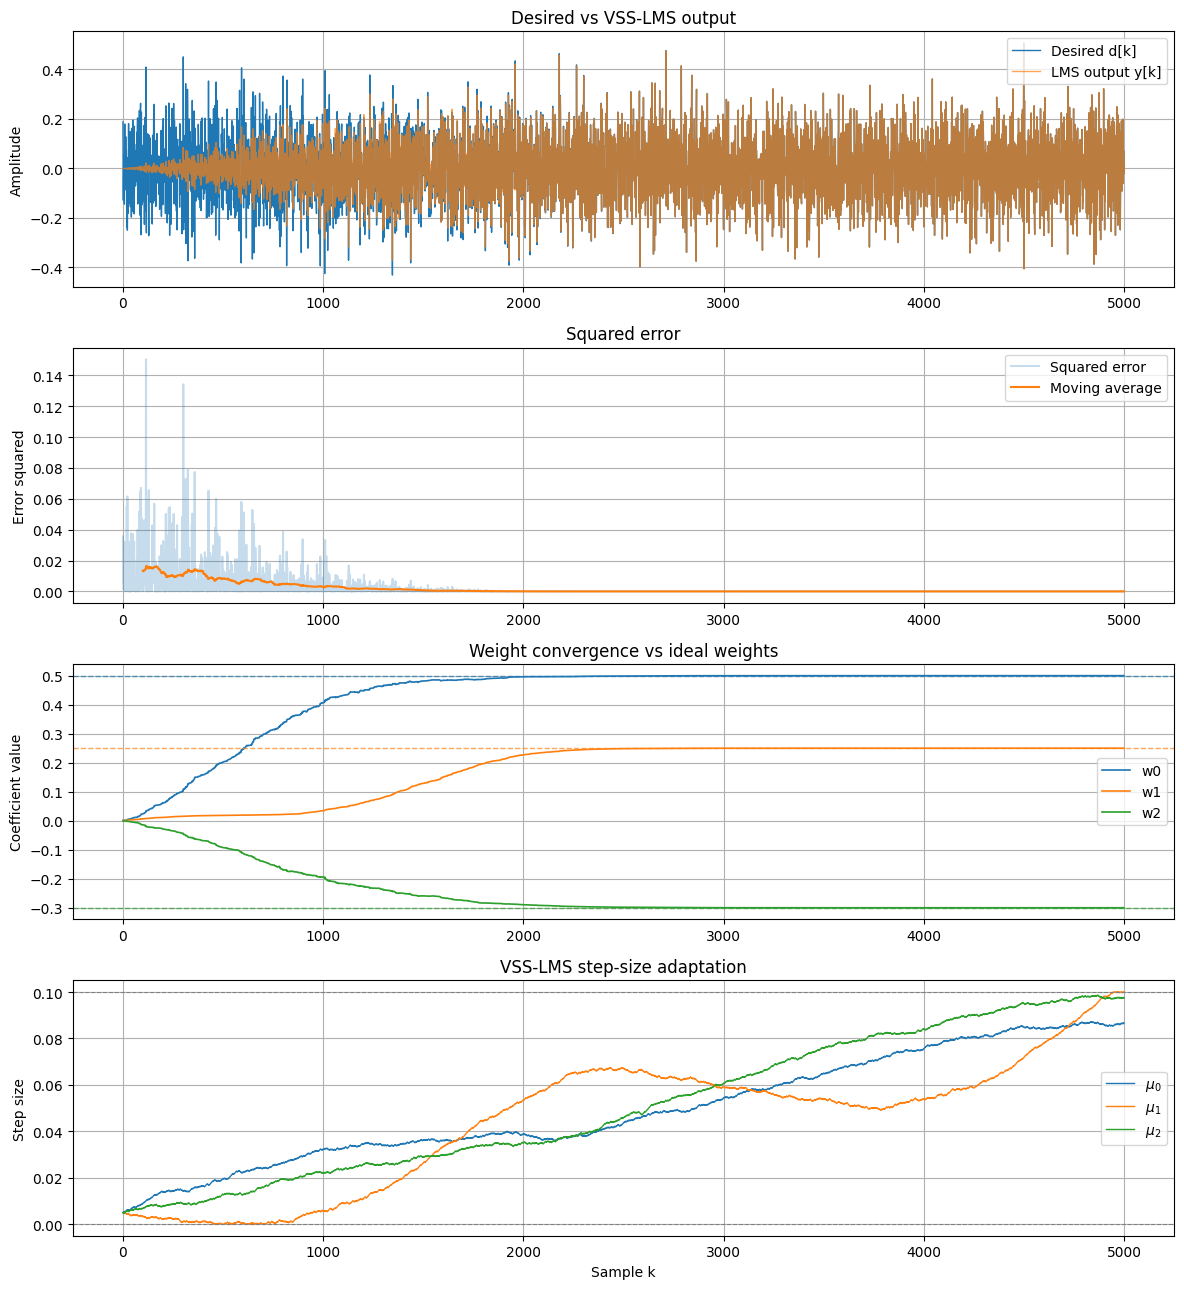

In [15]:
#LMS variable step sise

import numpy as np
import matplotlib.pyplot as plt

N = 5000 # samples
M = 3 # tabs
MU_init = 0.005 #inital value
MU_max = 0.10
MU_min = 0.00005
rho = 0.0001

h = np.array([0.5,0.25,-0.3])
seed = 11
noise_std = 0.2

rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)

use_sinus = False
sin_amp = 1.0
sin_f = 0.05
if use_sinus:
    x += sin_amp*np.sin(2*np.pi * sin_f*k)

d = np.convolve(x,h,mode="full")[:N]

results = {}
w = np.zeros(M)
y = np.zeros(N)
e = np.zeros(N)
g_i = np.zeros(M)
u_i = np.zeros(M)
mu = np.full(M, MU_init)
g_old = np.zeros(M)

w_history = np.zeros((N,M))
mu_history = np.zeros((N,M))

for k in range(M-1, N):
    x_vec = x[k-M+1:k+1][::-1]

    y[k] = np.dot(w,x_vec)

    e[k] = d[k] - y[k]

    #update tap weights and step size parameters (from slide #42)
    for i in range(M):

        g = e[k] * x[k-i] #gradient contribution

        #update individual step size
        if k > M - 1:
            mu[i] += rho * np.sign(g) * np.sign(g_old[i])

        #limit
        mu[i] = np.clip(mu[i], MU_min, MU_max)

        w[i] += 2* mu[i] * g

        g_old[i] = g

    w_history[k] = w
    mu_history[k] = mu


#===============================================
#plot stuff

fig, axs = plt.subplots(4, 1, figsize=(12, 13))

samples = np.arange(M-1, N)

# 1. Desired output vs adaptive output
axs[0].plot(samples, d[M-1:], label="Desired d[k]",
            linewidth=1)
axs[0].plot(samples, y[M-1:], label="LMS output y[k]",
            linewidth=1, alpha=0.7)

axs[0].set_title("Desired vs VSS-LMS output")
axs[0].set_ylabel("Amplitude")
axs[0].legend()
axs[0].grid(True)


# 2. Squared error and smoothed squared error
squared_error = e[M-1:]**2
window = 100

mse_moving = np.convolve(
    squared_error,
    np.ones(window) / window,
    mode="valid"
)

axs[1].plot(samples, squared_error,
            label="Squared error", alpha=0.25)

axs[1].plot(samples[window-1:], mse_moving,
            label="Moving average", linewidth=1.5)

axs[1].set_title("Squared error")
axs[1].set_ylabel("Error squared")
axs[1].legend()
axs[1].grid(True)


# 3. Weight convergence
for i in range(M):

    axs[2].plot(samples, w_history[M-1:, i],
                label=f"w{i}", linewidth=1.2)

    # Actual coefficients
    if i < len(h):
        axs[2].axhline(
            h[i], linestyle="--",
            linewidth=1, color=f"C{i}",
            alpha=0.7
        )

    else:
        axs[2].axhline(
            0, linestyle="--",
            linewidth=1, color=f"C{i}",
            alpha=0.7
        )

axs[2].set_title("Weight convergence vs ideal weights")
axs[2].set_ylabel("Coefficient value")
axs[2].legend()
axs[2].grid(True)


# 4. Step-size adaptation
for i in range(M):

    axs[3].plot(samples, mu_history[M-1:, i],
                label=f"$\\mu_{i}$", linewidth=1)

axs[3].axhline(MU_max, linestyle="--",
               color="gray", linewidth=0.8)

axs[3].axhline(MU_min, linestyle="--",
               color="gray", linewidth=0.8)

axs[3].set_title("VSS-LMS step-size adaptation")
axs[3].set_ylabel("Step size")
axs[3].set_xlabel("Sample k")
axs[3].legend()
axs[3].grid(True)

plt.tight_layout()
plt.show()

